# Compare the geolytix supermarkets to foursquare POIs 
remake some of the analysis in this paper:
https://arxiv.org/abs/2310.18415

more refinement would be needed to make sure we are getting the same sets from foursquare but good start.

In [2]:
import geopandas as gpd
import pandas as pd
import re
import numpy as np
import matplotlib.pyplot as plt
# Load data

retail_landuse = gpd.read_parquet("../data/input_files/retail_landuse.parquet")
foursquare_pois = gpd.read_parquet("../data/input_files/uk_foursquare_cc_aug.parquet")
#drop anything with a date_closed
foursquare_pois = foursquare_pois[foursquare_pois["date_closed"].isna()].copy()
retail_park_stores = pd.read_csv("../data/input_files/bl_retail_parks_brands_deduped.csv")
geolytix_supermarkets = pd.read_csv("../data/input_files/geolytix_retailpoints_v36_202506.csv")

#convert geolytix_supermarkets to a geodataframe using long_wgs and lat_wgs
geolytix_supermarkets = gpd.GeoDataFrame(geolytix_supermarkets, geometry=gpd.points_from_xy(geolytix_supermarkets.long_wgs, geolytix_supermarkets.lat_wgs), crs="EPSG:4326")
geolytix_supermarkets.to_parquet("../data/input_files/geolytix_supermarkets.parquet")

geolytix_supermarkets

,id,retailer,fascia,store_name,add_one,add_two,town,suburb,postcode,long_wgs,lat_wgs,bng_e,bng_n,pqi,open_date,size_band,county,geometry
0,1010020082,Spar,Spar PFS,Spar - Elstow Road,3 Elstow Road,NaN,Bedford,Cauldwell,MK42 9NU,-0.465765,52.124119,505131.403163,248421.668911,Rooftop,NaN,"< 3,013 ft2 (280m2)",Bedfordshire,POINT (-0.46577 52.12412)
1,1010018763,Morrisons,Morrisons Daily,Morrisons Daily Grands Vaux,Grand Vaux,NaN,Jersey,NaN,JE2 4NA,-2.096155,49.197940,392995.548761,-77993.009542,Rooftop,20209999.0,"< 3,013 ft2 (280m2)",NaN,POINT (-2.09616 49.19794)
2,1010014192,Heron,Heron,Heron Egremont,35 Main Street,NaN,Egremont,NaN,CA22 2DR,-3.528035,54.482488,301098.533515,510757.057669,Rooftop,NaN,"< 3,013 ft2 (280m2)",Cumbria,POINT (-3.52803 54.48249)
3,1010018120,Spar,Spar,Spar - Lambeg,163 Queensway,NaN,Lisburn,Hilden,BT27 4QS,-6.031195,54.527804,139271.259108,522203.209893,Rooftop,NaN,"< 3,013 ft2 (280m2)",Down,POINT (-6.0312 54.5278)
4,1010018212,Spar,Spar,Spar - Grand Street Lisburn,92 Grand St,NaN,Lisburn,Hilden,BT27 4UE,-6.028092,54.516700,139401.125645,520957.190143,Rooftop,NaN,"< 3,013 ft2 (280m2)",Down,POINT (-6.02809 54.5167)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19124,1010005425,Tesco,Tesco Express,Tesco High St Banbury Express,23 High Street,NaN,Banbury,Central Banbury,OX16 5EG,-1.337013,52.060688,445550.761260,240463.888285,Rooftop,NaN,"< 3,013 ft2 (280m2)",Oxfordshire,POINT (-1.33701 52.06069)
19125,1010000370,Aldi,Aldi,Aldi Ruscote Banbury,Ruscote Avenue,NaN,Banbury,Ruscote,OX16 2GU,-1.346162,52.070801,444913.441258,241583.028288,Rooftop,NaN,"3,013 < 15,069 ft2 (280 < 1,400 m2)",Oxfordshire,POINT (-1.34616 52.0708)
19126,1010013515,Marks and Spencer,Marks and Spencer,M&S Gateway M40 Banbury,Unit 11 Gateway Retail Park,NaN,Banbury,Grimsbury,OX16 3XS,-1.318864,52.077575,446777.481263,242353.598295,Rooftop,20169999.0,"15,069 < 30,138 ft2 (1,400 < 2,800 m2)",Oxfordshire,POINT (-1.31886 52.07757)
19127,1010003136,Sainsburys,Sainsburys,Sainsburys Banbury,Oxford Road,NaN,Banbury,Central Banbury,OX16 9XA,-1.333385,52.050615,445809.801261,239345.788281,Rooftop,NaN,"30,138 ft2 > (2,800 m2)",Oxfordshire,POINT (-1.33338 52.05062)


In [3]:
#split the supermarkets into ones in a retail landuse polygon and ones not in a retail landuse polygon
geolytix_supermarkets_in_retail = gpd.sjoin(geolytix_supermarkets, retail_landuse, how="inner", predicate="within").drop(columns=["index_right"])
geolytix_supermarkets_not_in_retail = gpd.sjoin(geolytix_supermarkets, retail_landuse, how="left", predicate="within")
geolytix_supermarkets_not_in_retail = geolytix_supermarkets_not_in_retail[geolytix_supermarkets_not_in_retail["index_right"].isna()].drop(columns=["index_right"])

print(f"Number of supermarkets in retail landuse polygons: {len(geolytix_supermarkets_in_retail)}")
print(f"Number of supermarkets not in retail landuse polygons: {len(geolytix_supermarkets_not_in_retail)}")

Number of supermarkets in retail landuse polygons: 8922
Number of supermarkets not in retail landuse polygons: 10257


In [4]:
# #filter for grocery stores or supermarkets in foursquare or petrol stations
foursquare_pois = foursquare_pois[
    foursquare_pois["fsq_category_id"].isin([
        "52f2ab2ebcbc57f1066b8b46",
        "4bf58dd8d48988d118951735",
#   "52f2ab2ebcbc57f1066b8b46"

    ])
].drop_duplicates(subset=["fsq_place_id"]).copy()

geo_total = len(geolytix_supermarkets)
fsq_total = len(foursquare_pois)
perc_total = (geo_total - fsq_total) / geo_total * 100 if geo_total else float("nan")
print(f"Total: geolytix={geo_total}, foursquare={fsq_total}, perc_diff={perc_total:.1f}%")

def report(label, geo_df, fsq_df):
    g = len(geo_df)
    f = len(fsq_df)
    pct = (f-g) / g * 100 if g else float("nan")
    print(f"{label}: geolytix={g}, foursquare={f}, perc_diff={pct:.1f}%")

# Waitrose
geolytix_waitrose = geolytix_supermarkets[
    geolytix_supermarkets["retailer"].str.contains(r"\bWaitrose\b", flags=re.IGNORECASE, na=False)
].copy()
foursquare_waitrose = foursquare_pois[
    foursquare_pois["name"].str.contains(r"\bWaitrose\b", flags=re.IGNORECASE, na=False)
].copy()
report("Waitrose", geolytix_waitrose, foursquare_waitrose)

# Spar
geolytix_spar = geolytix_supermarkets[
    geolytix_supermarkets["retailer"].str.contains(r"\bSpar\b", flags=re.IGNORECASE, na=False)
].copy()
foursquare_spar = foursquare_pois[
    foursquare_pois["name"].str.contains(r"\bSpar\b", flags=re.IGNORECASE, na=False)
].copy()
report("Spar", geolytix_spar, foursquare_spar)

# Tesco
geolytix_tesco = geolytix_supermarkets[
    geolytix_supermarkets["retailer"].str.contains(r"\bTesco\b", flags=re.IGNORECASE, na=False)
].copy()
foursquare_tesco = foursquare_pois[
    foursquare_pois["name"].str.contains(r"\bTesco\b", flags=re.IGNORECASE, na=False)
].copy()
report("Tesco", geolytix_tesco, foursquare_tesco)

# Aldi
geolytix_aldi = geolytix_supermarkets[
    geolytix_supermarkets["retailer"].str.contains(r"\bAldi\b", flags=re.IGNORECASE, na=False)
].copy()
foursquare_aldi = foursquare_pois[
    foursquare_pois["name"].str.contains(r"\bAldi\b", flags=re.IGNORECASE, na=False)
].copy()
report("Aldi", geolytix_aldi, foursquare_aldi)

# Lidl
geolytix_lidl = geolytix_supermarkets[
    geolytix_supermarkets["retailer"].str.contains(r"\bLidl\b", flags=re.IGNORECASE, na=False)
].copy()
foursquare_lidl = foursquare_pois[
    foursquare_pois["name"].str.contains(r"\bLidl\b", flags=re.IGNORECASE, na=False)
].copy()
report("Lidl", geolytix_lidl, foursquare_lidl)

# Morrisons
geolytix_morrisons = geolytix_supermarkets[
    geolytix_supermarkets["retailer"].str.contains(r"\bMorrisons\b", flags=re.IGNORECASE, na=False)
].copy()
foursquare_morrisons = foursquare_pois[
    foursquare_pois["name"].str.contains(r"\bMorrisons\b", flags=re.IGNORECASE, na=False)
].copy()
report("Morrisons", geolytix_morrisons, foursquare_morrisons)

# Co-op
geolytix_coop = geolytix_supermarkets[
    geolytix_supermarkets["retailer"].str.contains(r"\bThe Co-operative Group\b", flags=re.IGNORECASE, na=False)
].copy()
foursquare_coop = foursquare_pois[
    foursquare_pois["name"].str.contains(r"\bCo-op\b", flags=re.IGNORECASE, na=False)
].copy()
report("Co-op", geolytix_coop, foursquare_coop)

# Sainsbury's
geolytix_sainsburys = geolytix_supermarkets[
    geolytix_supermarkets["retailer"].str.contains(r"\bSainsburys\b", flags=re.IGNORECASE, na=False)
].copy()
foursquare_sainsburys = foursquare_pois[
    foursquare_pois["name"].str.contains(r"\bSainsbury's\b", flags=re.IGNORECASE, na=False)
].copy()
report("Sainsbury's", geolytix_sainsburys, foursquare_sainsburys)

# Asda
geolytix_asda = geolytix_supermarkets[
    geolytix_supermarkets["retailer"].str.contains(r"\bAsda\b", flags=re.IGNORECASE, na=False)
].copy()
foursquare_asda = foursquare_pois[
    foursquare_pois["name"].str.contains(r"\bAsda\b", flags=re.IGNORECASE, na=False)
].copy()
report("Asda", geolytix_asda, foursquare_asda)

# Iceland
geolytix_iceland = geolytix_supermarkets[
    geolytix_supermarkets["retailer"].str.contains(r"\bIceland\b", flags=re.IGNORECASE, na=False)
].copy()
foursquare_iceland = foursquare_pois[
    foursquare_pois["name"].str.contains(r"\bIceland\b", flags=re.IGNORECASE, na=False)
].copy()
report("Iceland", geolytix_iceland, foursquare_iceland)

Total: geolytix=19129, foursquare=37814, perc_diff=-97.7%
Waitrose: geolytix=426, foursquare=458, perc_diff=7.5%
Spar: geolytix=2226, foursquare=2507, perc_diff=12.6%
Tesco: geolytix=2932, foursquare=3034, perc_diff=3.5%
Aldi: geolytix=1050, foursquare=1202, perc_diff=14.5%
Lidl: geolytix=1025, foursquare=1161, perc_diff=13.3%
Morrisons: geolytix=1792, foursquare=943, perc_diff=-47.4%
Co-op: geolytix=2417, foursquare=4370, perc_diff=80.8%
Sainsbury's: geolytix=1462, foursquare=1543, perc_diff=5.5%
Asda: geolytix=1106, foursquare=629, perc_diff=-43.1%
Iceland: geolytix=969, foursquare=1048, perc_diff=8.2%


In [6]:
def nearest_match_within(pois_gdf, stores_gdf, max_distance=None, return_crs="EPSG:4326"):
  """
  Simpler nearest spatial join (point -> point) with a max distance cutoff.

  Parameters
  - pois_gdf: GeoDataFrame of POIs (points)
  - stores_gdf: GeoDataFrame of reference stores (points)
  - max_distance: maximum distance in meters for a match
  - return_crs: CRS of returned GeoDataFrame (None to keep projected CRS)

  Uses notebook variable `projected_crs` if present, otherwise falls back to EPSG:27700.
  Returns joined GeoDataFrame (contains column 'dist_m').
  """
  pois = pois_gdf.copy()
  stores = stores_gdf.copy()

  # prefer stores CRS if one is missing
  if pois.crs is None and stores.crs is not None:
    pois = pois.set_crs(stores.crs, allow_override=True)
  if stores.crs is None and pois.crs is not None:
    stores = stores.set_crs(pois.crs, allow_override=True)

  proj_crs = globals().get("projected_crs", "EPSG:27700")

  pois_proj = pois.to_crs(proj_crs)
  stores_proj = stores.to_crs(proj_crs)

  joined = gpd.sjoin_nearest(
    pois_proj,
    stores_proj,
    how="inner",
    max_distance=max_distance,
    distance_col="dist_m",
  )

  #plot the distances
  joined["dist_m"].hist(bins=30)
  plt.show()

  #print the median distance
  print("Median distance (m):", joined["dist_m"].median())
  if return_crs is not None and not joined.empty:
    joined = joined.to_crs(return_crs)

  return joined


Waitrose


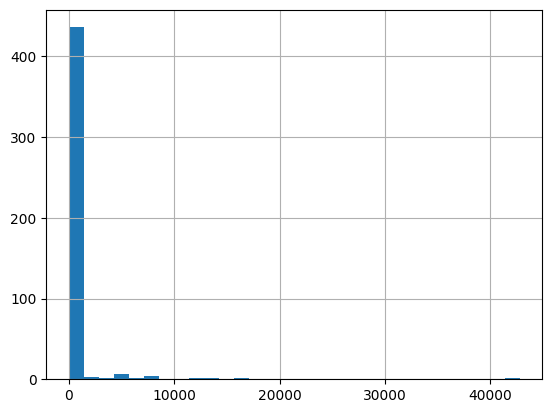

Median distance (m): 10.598055111347104
Aldi


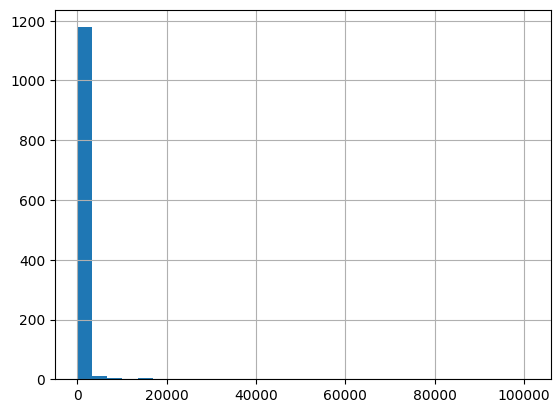

Median distance (m): 20.103009984447475
Spar


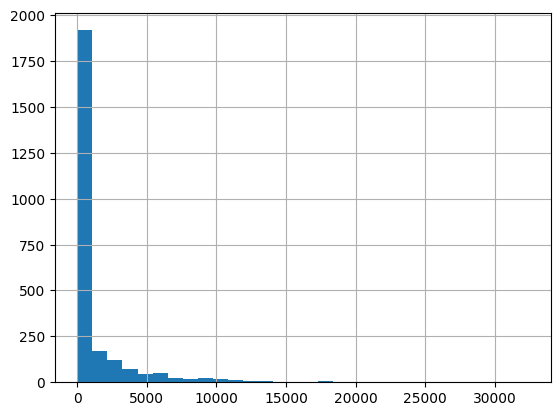

Median distance (m): 37.51444872869008
Tesco


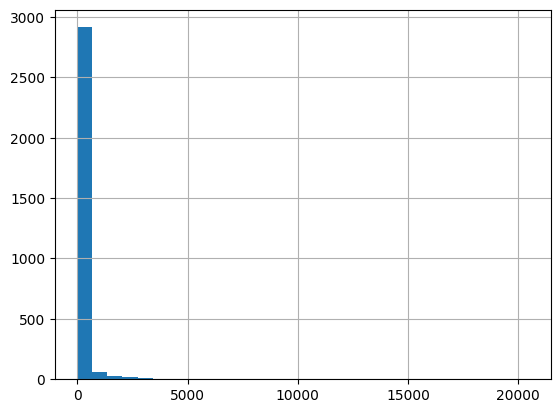

Median distance (m): 7.6883023232635885
Lidl


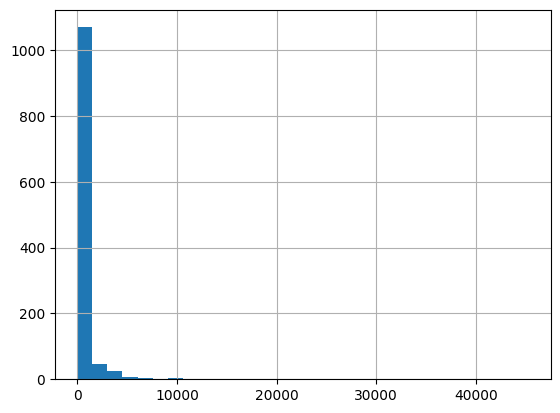

Median distance (m): 39.48425896836143
Morrisons


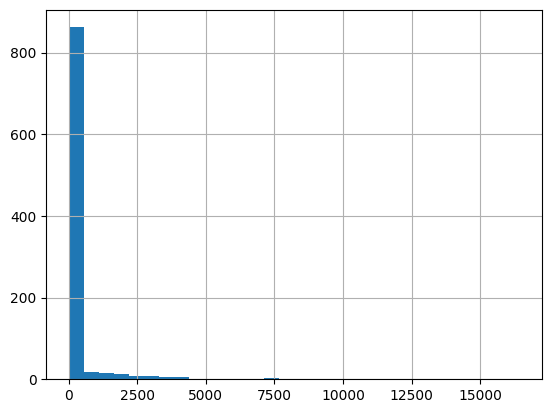

Median distance (m): 34.076617084235515
Co-op


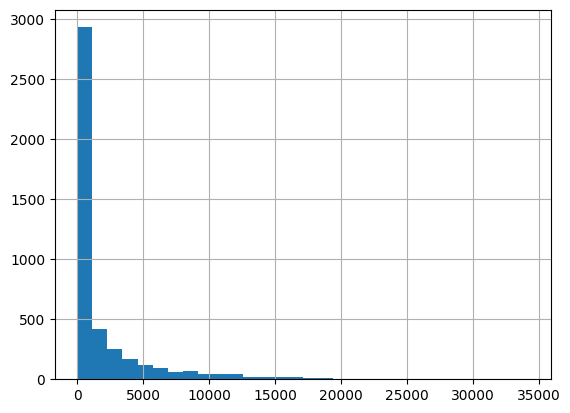

Median distance (m): 23.38662665523781
Sainsbury's


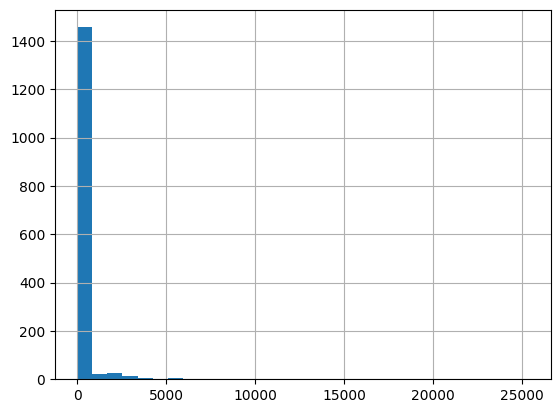

Median distance (m): 9.203183305385878
Asda


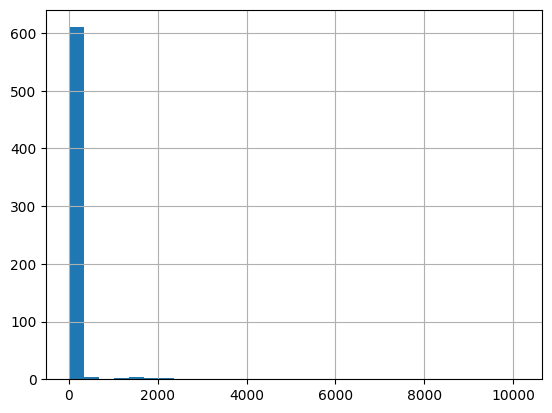

Median distance (m): 19.856949720351587


In [7]:
print("Waitrose")
joined_waitrose = nearest_match_within(foursquare_waitrose, geolytix_waitrose)

print("Aldi")
joined_aldi = nearest_match_within(foursquare_aldi, geolytix_aldi)

print("Spar")
joined_spar = nearest_match_within(foursquare_spar, geolytix_spar)

print("Tesco")
joined_tesco = nearest_match_within(foursquare_tesco, geolytix_tesco)

print("Lidl")
joined_lidl = nearest_match_within(foursquare_lidl, geolytix_lidl)

print("Morrisons")
joined_morrisons = nearest_match_within(foursquare_morrisons, geolytix_morrisons)

print("Co-op")
joined_coop = nearest_match_within(foursquare_coop, geolytix_coop)

print("Sainsbury's")
joined_sainsburys = nearest_match_within(foursquare_sainsburys, geolytix_sainsburys)

print("Asda")
joined_asda = nearest_match_within(foursquare_asda, geolytix_asda)

In [ ]:
#Tesco stores with no match within 100m in foursquare

joined_tesco_no_match = joined_tesco[joined_tesco["dist_m"]>100]
joined_tesco_no_match

In [9]:
import geopandas as gpd
import matplotlib.pyplot as plt

def nearest_distances_then_cut(pois_gdf, stores_gdf, threshold_m=None, return_crs="EPSG:4326"):
    """
    For each store, compute the nearest POI and the distance (meters) with NO cutoff.
    Then (optionally) return the subset of stores whose nearest POI is farther than `threshold_m`.

    Returns:
      joined_all, unmatched_by_threshold
        - joined_all: GeoDataFrame of stores joined to their single nearest POI with 'dist_m'
        - unmatched_by_threshold: subset of joined_all where dist_m > threshold_m
                                  (or empty if threshold_m is None)
    """
    stores = stores_gdf.copy()
    pois = pois_gdf.copy()

    # prefer stores CRS if one is missing
    if pois.crs is None and stores.crs is not None:
        pois = pois.set_crs(stores.crs, allow_override=True)
    if stores.crs is None and pois.crs is not None:
        stores = stores.set_crs(pois.crs, allow_override=True)

    proj_crs = globals().get("projected_crs", "EPSG:27700")

    # project to a metric CRS for meters
    stores_proj = stores.to_crs(proj_crs)
    pois_proj = pois.to_crs(proj_crs)

    if pois_proj.empty:
        # no POIs: distances cannot be computed; just return stores with NaN dist
        joined_all = stores_proj.copy()
        joined_all["dist_m"] = float("nan")
    else:
        # compute nearest for *all* stores (no max_distance)
        joined_all = gpd.sjoin_nearest(
            stores_proj,
            pois_proj,
            how="left",
            distance_col="dist_m",
        )

    # bring back to requested CRS
    if return_crs is not None and not joined_all.empty:
        joined_all = joined_all.to_crs(return_crs)

    # filter AFTER computing all distances
    if threshold_m is None:
        unmatched_by_threshold = joined_all.iloc[0:0].copy()  # empty, same schema
    else:
        unmatched_by_threshold = joined_all[joined_all["dist_m"].isna() | (joined_all["dist_m"] > threshold_m)].copy()

    # quick sanity print
    if threshold_m is not None:
        print(f"Stores with nearest POI farther than {threshold_m} m: {len(unmatched_by_threshold)} / {len(joined_all)}")

    return joined_all, unmatched_by_threshold



In [ ]:
#geolytix the dont match foursquare (200m is quite harsh in terms of exististence)

print("Aldi")
all,unmatched =nearest_distances_then_cut(foursquare_aldi, geolytix_aldi, threshold_m=200)
print("Waitrose")
all,unmatched =nearest_distances_then_cut(foursquare_waitrose, geolytix_waitrose, threshold_m=200)
print("Spar")
all,unmatched =nearest_distances_then_cut(foursquare_spar, geolytix_spar, threshold_m=200)
print("Tesco")
all,unmatched =nearest_distances_then_cut(foursquare_tesco, geolytix_tesco, threshold_m=200)
print("Lidl")
all,unmatched =nearest_distances_then_cut(foursquare_lidl, geolytix_lidl, threshold_m=200)
print("Morrisons")
all,unmatched =nearest_distances_then_cut(foursquare_morrisons, geolytix_morrisons, threshold_m=200)
print("Co-op")
all,unmatched =nearest_distances_then_cut(foursquare_coop, geolytix_coop, threshold_m=200)
print("Sainsbury's")
all,unmatched =nearest_distances_then_cut(foursquare_sainsburys, geolytix_sainsburys, threshold_m=200)
print("Asda")
all,unmatched =nearest_distances_then_cut(foursquare_asda, geolytix_asda, threshold_m=200)
print("Iceland")
all,unmatched =nearest_distances_then_cut(foursquare_iceland, geolytix_iceland, threshold_m=200)
unmatched



Stores with nearest POI farther than 200 m: 70 / 1051
Stores with nearest POI farther than 200 m: 24 / 427
Stores with nearest POI farther than 200 m: 668 / 2229
Stores with nearest POI farther than 200 m: 206 / 2938
Stores with nearest POI farther than 200 m: 53 / 1027
Stores with nearest POI farther than 200 m: 974 / 1792
Stores with nearest POI farther than 200 m: 147 / 2423
Stores with nearest POI farther than 200 m: 91 / 1462
Stores with nearest POI farther than 200 m: 507 / 1106
Stores with nearest POI farther than 200 m: 184 / 969


,id,retailer,fascia,store_name,add_one,add_two,town,suburb,postcode_left,long_wgs,...,level2_category_name,level3_category_id,level3_category_name,level4_category_id,level4_category_name,level5_category_id,level5_category_name,level6_category_id,level6_category_name,dist_m
332,1010010999,Iceland,Iceland,Iceland Newry,28-30 Monaghan Street,NaN,Newry,Central Newry,BT35 6AA,-6.343209,...,Food and Beverage Retail,4bf58dd8d48988d118951735,Grocery Store,None,None,None,None,None,None,246.624391
386,1010010979,Iceland,Iceland,Iceland Ballymena,35-43 High Street,NaN,Ballymena,Central Ballymena,BT43 6DT,-6.274548,...,Food and Beverage Retail,4bf58dd8d48988d118951735,Grocery Store,None,None,None,None,None,None,258.540082
419,1010016181,Iceland,The Food Warehouse,Iceland Newtonabbey Food Warehouse,Unit 3 Longwood Retail Park,NaN,Newtownabbey,Abbey,BT37 9UF,-5.916844,...,Food and Beverage Retail,4bf58dd8d48988d118951735,Grocery Store,None,None,None,None,None,None,264.569594
624,1010015966,Iceland,The Food Warehouse,Iceland Coatbridge Food Warehouse,Unit 3 Faraday Retail Park,NaN,Coatbridge,Cliftonville,ML5 3SQ,-4.022410,...,Food and Beverage Retail,4bf58dd8d48988d118951735,Grocery Store,None,None,None,None,None,None,2886.197180
685,1010015466,Iceland,Iceland,Iceland Burnley Charter Walk,Unit 42A The Mall,Charter Walk Shopping Centre,Burnley,Central Burnley,BB11 1AE,-2.243300,...,Food and Beverage Retail,4bf58dd8d48988d118951735,Grocery Store,None,None,None,None,None,None,396.524118
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18623,1010011194,Iceland,Iceland,Iceland Kensington,Prescot Road,NaN,Liverpool,Fairfield,L7 0LQ,-2.943837,...,Food and Beverage Retail,4bf58dd8d48988d118951735,Grocery Store,None,None,None,None,None,None,946.498383
18749,1010015959,Iceland,The Food Warehouse,Iceland Clydebank Food Warehouse,Unit 6 Clydebank Retail Park,NaN,Clydebank,Clydebank,G81 2XA,-4.396000,...,Food and Beverage Retail,4bf58dd8d48988d118951735,Grocery Store,None,None,None,None,None,None,551.438901
18751,1010011315,Iceland,Iceland,Iceland Clydebank,35-37 Sylvania Way,South Clydebank Shopping Centr,Clydebank,Clydebank,G81 1EA,-4.403779,...,Food and Beverage Retail,4bf58dd8d48988d118951735,Grocery Store,None,None,None,None,None,None,353.795436
18819,1010015970,Iceland,The Food Warehouse,Iceland Corby Food Warehouse,Unit 1 Peel Retail Park,Phoenix Way,Corby,Earlstrees Industry,NN17 5DT,-0.682214,...,Food and Beverage Retail,4bf58dd8d48988d118951735,Grocery Store,None,None,None,None,None,None,1618.483157


In [11]:
#reverse - foursquare the dont match geolytix (200m is quite harsh in terms of exististence)
#reverse - foursquare the dont match geolytix (200m is quite harsh in terms of exististence)
print("Aldi")
all, unmatched = nearest_distances_then_cut(geolytix_aldi, foursquare_aldi, threshold_m=200)

print("Waitrose")
all, unmatched = nearest_distances_then_cut(geolytix_waitrose, foursquare_waitrose, threshold_m=200)

print("Spar")
all, unmatched = nearest_distances_then_cut(geolytix_spar, foursquare_spar, threshold_m=200)

print("Tesco")
all, unmatched = nearest_distances_then_cut(geolytix_tesco, foursquare_tesco, threshold_m=200)

print("Lidl")
all, unmatched = nearest_distances_then_cut(geolytix_lidl, foursquare_lidl, threshold_m=200)

print("Morrisons")
all, unmatched = nearest_distances_then_cut(geolytix_morrisons, foursquare_morrisons, threshold_m=200)

print("Co-op")
all, unmatched = nearest_distances_then_cut(geolytix_coop, foursquare_coop, threshold_m=200)

print("Sainsbury's")
all, unmatched = nearest_distances_then_cut(geolytix_sainsburys, foursquare_sainsburys, threshold_m=200)

print("Iceland")
all, unmatched = nearest_distances_then_cut(geolytix_iceland, foursquare_iceland, threshold_m=200)

print("Asda")
all, unmatched = nearest_distances_then_cut(geolytix_asda, foursquare_asda, threshold_m=200)

unmatched

Aldi
Stores with nearest POI farther than 200 m: 167 / 1202
Waitrose
Stores with nearest POI farther than 200 m: 31 / 458
Spar
Stores with nearest POI farther than 200 m: 868 / 2511
Tesco
Stores with nearest POI farther than 200 m: 201 / 3034
Lidl
Stores with nearest POI farther than 200 m: 175 / 1161
Morrisons
Stores with nearest POI farther than 200 m: 104 / 943
Co-op
Stores with nearest POI farther than 200 m: 1888 / 4370
Sainsbury's
Stores with nearest POI farther than 200 m: 125 / 1543
Iceland
Stores with nearest POI farther than 200 m: 254 / 1048
Asda
Stores with nearest POI farther than 200 m: 26 / 629


,fsq_place_id,name,lat,lng,address,locality,region,postcode_left,admin_region,post_town,...,postcode_right,long_wgs,lat_wgs,bng_e,bng_n,pqi,open_date,size_band,county,dist_m
200654,11c25dbc7a4248167b7c1506,Asda,51.454614,0.256185,Galleon Boulevard Unit 8,Dartford,Kent,DA2 6QE,England,Dartford,...,DA9 9BT,0.276950,51.452475,558305.661578,175068.828238,Rooftop,NaN,"30,138 ft2 > (2,800 m2)",Kent,1462.797502
262799,55ed7f33498e94255dfa3a9f,Asda,51.395339,0.552730,Pier Rd,Gillingham,Kent,ME7 1RZ,England,None,...,ME7 1RZ,0.552745,51.397624,577678.580823,169601.753652,Rooftop,20150907.0,"30,138 ft2 > (2,800 m2)",Kent,254.221740
269210,4bc1da0e4cdfc9b6841b9521,Asda,51.352011,0.737553,Mill Way - Trinity Trading Estate,Sittingbourne,Kent,ME10 2PD,England,None,...,ME10 2PD,0.741866,51.351522,591024.391653,164951.178257,Rooftop,NaN,"30,138 ft2 > (2,800 m2)",Kent,305.317829
880288,ae86b895073e418344ed821e,Asda Collection Point,51.465879,-3.176202,Corporation Rd,Middlesbrough,North Yorkshire,CF11 7AS,Wales,Cardiff,...,CF11 0JR,-3.184562,51.455893,317792.490842,173656.117795,Rooftop,NaN,"30,138 ft2 > (2,800 m2)",South Glamorgan,1253.421656
1090997,4b6708f4f964a52020362be3,Asda,52.590175,-2.128437,Jack Hayward Way - Waterloo Road,Wolverhampton,Wolverhampton,WV1 4DE,England,None,...,WV1 4DE,-2.128754,52.592584,391374.991066,299428.398439,Rooftop,NaN,"30,138 ft2 > (2,800 m2)",West Midlands,268.784612
1147555,ae764ee3cbfe4a679937d1e9,Asda Collection Point,52.434826,-1.603948,A45 Birmingham Rd,Coventry,West Midlands,CV5 9GY,England,Coventry,...,CV6 3EX,-1.518211,52.430434,432854.751209,281492.768431,Rooftop,NaN,"3,013 < 15,069 ft2 (280 < 1,400 m2)",West Midlands,5849.622940
1717950,7093092f7e8641a0d82fcf45,Asda Superstore,50.903086,-1.405542,Portland Terrace,Southampton,Hampshire,SO14 7EG,England,Southampton,...,SO14 7EG,-1.407354,50.905870,441767.241264,111989.187785,Rooftop,NaN,"30,138 ft2 > (2,800 m2)",Hampshire,334.830310
1891274,b8e4151994da4c92fdd6b8fc,Asda Collection Point,51.400804,-0.076572,Holmesdale Rd,London,Greater London,SE25 6BS,England,London,...,CR0 4XS,-0.130176,51.376859,530234.361508,165859.438153,Rooftop,NaN,"30,138 ft2 > (2,800 m2)",Greater London,4584.036511
2214885,de1abe838324482eb12639dd,Asda,51.531561,-0.299587,"Enfield Home Shopping Centre, Southbury Rd",London,Greater London,EN1 1UP,England,Enfield,...,HA0 1JQ,-0.297450,51.535045,518184.220955,183166.835236,Rooftop,20231107.0,"< 3,013 ft2 (280m2)",Greater London,414.902967
2367108,4e2b273e45dd3272c80fd44a,Asda,51.573024,-0.070901,"158 Clapton Common, Stamford Hill",London,Greater London,E5 9AG,England,None,...,N15 4QD,-0.060961,51.587222,534431.711518,189377.338247,Rooftop,NaN,"15,069 < 30,138 ft2 (1,400 < 2,800 m2)",Greater London,1723.195916
